# Customer Churn - Modelling
Steps: import, load data, split, train Random Forest, evaluate, feature importance

## 1. Import packages

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

%matplotlib inline
sns.set(color_codes=True)

## 2. Load data

In [2]:
df = pd.read_csv("../data/data_for_modelling.csv")
df.head(3)

,id,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,pow_max,churn,offpeak_diff_dec_jan_energy,offpeak_diff_dec_jan_power,off_peak_peak_var_mean_diff,peak_mid_peak_var_mean_diff,off_peak_mid_peak_var_mean_diff,off_peak_peak_fix_mean_diff,peak_mid_peak_fix_mean_diff,off_peak_mid_peak_fix_mean_diff,off_peak_peak_var_max_monthly_diff,peak_mid_peak_var_max_monthly_diff,off_peak_mid_peak_var_max_monthly_diff,off_peak_peak_fix_max_monthly_diff,peak_mid_peak_fix_max_monthly_diff,off_peak_mid_peak_fix_max_monthly_diff,tenure,months_activ,months_to_end,months_modif_prod,months_renewal,channel_sales_MISSING,channel_sales_ewpakwlliwisiwduibdlfmalxowmwpci,channel_sales_foosdfpfkusacimwkcsosbicdxkicaua,channel_sales_lmkebamcaaclubfxadlmueccxoimlema,channel_sales_usilxuppasemubllopkaafesmlibmsdf,origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws,origin_up_ldkssxwpmemidmecebumciepifcamkci,origin_up_lxidpiddsbxsbosboudacockeimpuepw
0,24011ae4ebbe3035111d65fa7c15bc57,0.000000,4.739944,0.0,0.000000,0.0,0.444045,0.047073,0.040659,1.619163,1,0.0,25.44,25.44,2,678.99,43.648,1,0.020057,3.700961,0.024038,0.034219,0.058257,18.590255,7.45067,26.040925,0.060550,0.085483,0.146033,44.26693,8.145775,44.26693,3,30,6,2,6,0,0,1,0,0,0,0,1
1,d29c2c54acc38ff3c0614d0a653813dd,3.668479,0.000000,0.0,2.280920,0.0,1.237292,0.059075,0.000000,1.656207,0,0.0,16.38,16.38,1,18.89,13.800,0,-0.003767,0.177779,0.142485,0.007124,0.149609,44.311375,0.00000,44.311375,0.151367,0.085483,0.151367,44.44471,0.000000,44.44471,7,76,8,76,4,1,0,0,0,0,1,0,0
2,764c75f661154dac3a6c254cd082ea7d,2.736397,0.000000,0.0,1.689841,0.0,1.599009,0.066622,0.036589,1.656207,0,0.0,28.60,28.60,1,6.60,13.856,0,-0.004670,0.177779,0.082090,0.088421,0.170512,44.385450,0.00000,44.385450,0.084587,0.089162,0.172468,44.44471,0.000000,44.44471,6,68,4,68,8,0,0,1,0,0,1,0,0


## 3. Train / test split
75% train, 25% test.

In [3]:
# target and features (id is not a feature)
y = df["churn"]
X = df.drop(columns=["id", "churn"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(X_train.shape, X_test.shape)
y_test.value_counts()

(10954, 43) (3652, 43)


churn
0    3286
1     366
Name: count, dtype: int64

## 4. Train model
Random Forest with 1000 trees.

In [4]:
model = RandomForestClassifier(n_estimators=1000, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metri

## 5. Evaluation
Accuracy alone can mislead here (only ~10% churn), so we also check precision and recall.

In [5]:
predictions = model.predict(X_test)
tn, fp, fn, tp = metrics.confusion_matrix(y_test, predictions).ravel()

print(f"True positives:  {tp}")
print(f"False positives: {fp}")
print(f"True negatives:  {tn}")
print(f"False negatives: {fn}\n")

print(f"Accuracy:  {metrics.accuracy_score(y_test, predictions):.3f}")
print(f"Precision: {metrics.precision_score(y_test, predictions):.3f}")
print(f"Recall:    {metrics.recall_score(y_test, predictions):.3f}")

True positives:  19
False positives: 2
True negatives:  3284
False negatives: 347

Accuracy:  0.904
Precision: 0.905
Recall:    0.052


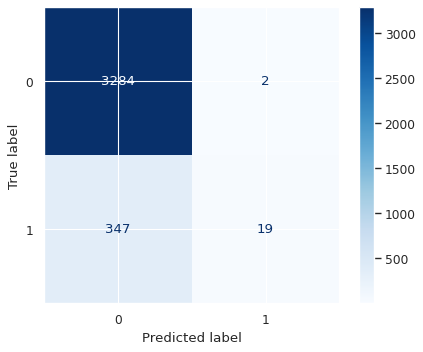

In [6]:
# confusion matrix plot
metrics.ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap="Blues")
plt.show()

- Accuracy is high (~90%) but misleading, since ~90% of clients don't churn.
- Precision is high: when the model says churn, it is usually right.
- Recall is very low: the model misses almost all real churners (many false negatives).
- The current features are not strong enough to separate churners. Next steps: more features, tuning, handling class imbalance.

## 6. Feature importance

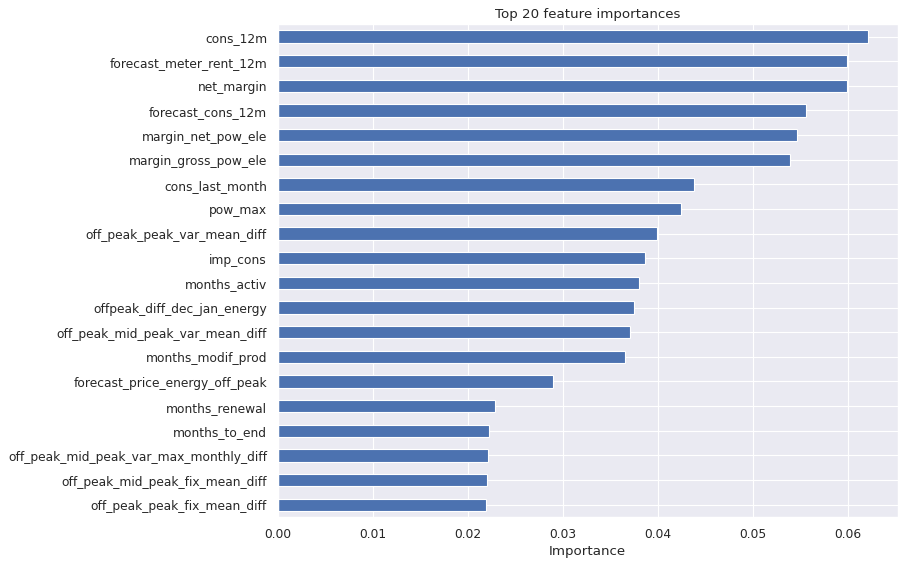

In [7]:
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values()

# top 20 only
importances.tail(20).plot(kind="barh", figsize=(10, 8), title="Top 20 feature importances")
plt.xlabel("Importance")
plt.show()

- Consumption, margins and meter rent are among the top drivers.
- Time features (e.g. `months_activ`) also matter.
- Price difference features show up in the top 20 but none dominates, so price sensitivity looks like a weak-to-moderate driver. More testing is needed for a firm answer.

## 7. Save predictions

In [8]:
# predicted class and churn probability for the test set
results = X_test.copy()
results["churn_actual"] = y_test
results["churn_predicted"] = predictions
results["churn_probability"] = model.predict_proba(X_test)[:, 1]
results.to_csv("../data/out_of_sample_data_with_predictions.csv", index=False)
results[["churn_actual", "churn_predicted", "churn_probability"]].head()

,churn_actual,churn_predicted,churn_probability
4947,0,0,0.127
5868,0,0,0.140
6805,0,0,0.032
1323,0,0,0.090
11759,0,0,0.055
